In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from torch.nn import functional as F
from IPython.display import clear_output

from neurogym.core import TrialEnv
from neurogym.utils.ngym_random import TruncExp
from neurogym.utils import scheduler, spaces
from neurogym.wrappers.block import ScheduleEnvs
from neurogym.wrappers import Monitor
from neurogym.utils import plot_env

warnings.filterwarnings("ignore")
clear_output()

In [2]:
class SwitchPerceptualDecisionMaking(TrialEnv):
    """Perceptual decision-making task.

    Two-alternative forced choice task where the agent integrates noisy stimuli
    to decide which option has a higher average value.

    The agent observes a noisy stimulus during the stimulus period, with varying
    coherence levels (signal strength). The correct response is the location with
    the stronger average evidence. There is not a specialized stimulus period, and the
    agent must respond quickly after the stimulus is presented.

    Args:
        dt: Timestep of the environment in milliseconds.
        dim_ring: Number of stimulus locations (or choices).
        rewards: Optional dictionary to override default rewards. The required keys are "abort",
            "correct", and "fail". Defaults to {"abort": -0.1, "correct": 1.0, "fail": 0.0}.
        timing: Optional dictionary to override default durations of task periods. The expected keys are
            "fixation", "stimulus" (required), "delay", and "decision" (required).
            Defaults to {"fixation": 100, "stimulus": 2000, "delay": 0, "decision": 100}.
        cohs: Optional list of coherence levels controlling task difficulty.
            Defaults to [0, 6.4, 12.8, 25.6, 51.2].
        sigma: Standard deviation of Gaussian noise added to stimulus.
        abort: If True, incorrect actions during fixation abort the trial.
    """

    metadata = {  # noqa: RUF012
        "paper_link": "https://www.jneurosci.org/content/12/12/4745",
        "paper_name": "The analysis of visual motion: a comparison of neuronal and psychophysical performance",
        "tags": ["perceptual", "two-alternative", "supervised"],
    }

    def __init__(
        self,
        dt: int = 100,
        dim_ring: int = 2,
        rewards: dict[str, float] | None = None,
        timing: dict[str, int | TruncExp] | None = None,
        cohs: list[float] | None = None,
        sigma: float = 1.0,
        abort: bool = False,
        n_stim_max: int = 10
    ) -> None:
        super().__init__(dt=dt)
        # print('Constructing PerceptualDecisionMaking environment with dt:', dt, 'ms')
        self.dt = dt
        self.dim_ring = dim_ring
        self.abort = abort

        self.rewards = {"abort": -0.1, "correct": 1.0, "fail": -0.5}
        if rewards:
            self.rewards.update(rewards)

        self.timing = {"fixation": 100}
        self.decision_time = 4200
        if timing:
            self.timing.update(timing)

        self.cohs = cohs or [6.4, 12.8, 19.2, 25.6]
        self.sigma = sigma / np.sqrt(self.dt)

        self.theta = np.linspace(0, 2 * np.pi, self.dim_ring, endpoint=False)
        self.choices = np.arange(self.dim_ring)

        self.n_stim_max = n_stim_max  # Number of stimuli to present
        self.time_per_stim = [500, 600, 700, 800]
        self.observation_space = spaces.Box(
            -np.inf,
            np.inf,
            shape=(1 + self.dim_ring,),
            dtype=np.float32,
            name={"fixation": 0, "stimulus": list(range(1, self.dim_ring + 1))},
        )
        self.action_space = spaces.Discrete(
            1 + self.dim_ring,
            name={"fixation": 0, "choice": list(range(1, self.dim_ring + 1))},
        )

    def _new_trial(self, **kwargs):
        """Generate a new trial with randomized ground truth and stimulus coherence.

        Sets up the trial timeline, generates a noisy stimulus centered around the
        ground truth direction, and assigns it to the appropriate observation period.
        """
        # trial = {
        #     "ground_truth": self.rng.choice(self.choices),
        #     "coh": self.rng.choice(self.cohs),
        # }

        time_stim = [self.rng.choice(self.time_per_stim) for _ in range(self.n_stim_max)]
        # print('tmax:', self._tmax)
        # print('time_stim:', time_stim)
        # print('time_cumsum:', np.cumsum(time_stim))
        # print('where:', np.where((np.cumsum(time_stim) >= self.decision_time)))
        index = np.where((np.cumsum(time_stim) >= self.decision_time))[0][0]
        # print('index:', index)
        time_last_stim = self.decision_time - np.sum(time_stim[:index])
        time_stim = np.array(time_stim[:index] + [time_last_stim])
        # print('time_stim:', time_stim)
        n_stim = index + 1
        self.n_stim = n_stim  # Store the number of stimuli for later use
        for i in range(n_stim):
            self.timing[f"decision_{i}"] = int(time_stim[i])

        ground_truth = self.rng.choice(self.choices, size=n_stim)
        coh = self.rng.choice(self.cohs, size=n_stim)

        trial = {
            "ground_truth": ground_truth,
            "coh": coh,
            "time_stim": time_stim,
            "sigma": self.sigma,
        }
        trial.update(kwargs)

        gt = trial["ground_truth"]
        coh = trial["coh"]
        stim_theta = self.theta[gt]
        # print('gt:', gt)
        # print('stim_theta:', stim_theta)

        periods = ["fixation"] + [f"decision_{i}" for i in range(n_stim)]
        # print('periods:', periods)
        self.add_period(periods)
        self.add_ob(1, period="fixation", where="fixation")
        for i in range(n_stim):
            stim = np.cos(self.theta - stim_theta[i]) * (coh[i] / 200) + 0.5
            self.add_ob(stim, period=f"decision_{i}", where="stimulus")
            self.add_randn(0, self.sigma, period=f"decision_{i}", where="stimulus")
            self.set_groundtruth(gt[i], period=f"decision_{i}", where="choice")

        # print('tmax:', self._tmax)
        return trial

    def test_new_trial(self, choice, coh):
        self._tmax = 0  # reset, self.tmax not reset so it can be used in step
        self._ob_built = False
        self._gt_built = False

        trial = {"ground_truth": choice,
            "coh": coh}
        gt = trial["ground_truth"]
        stim_theta = self.theta[gt]
        self.add_period(["fixation", "stimulus", "delay", "decision"])
        self.add_ob(1, period="fixation", where="fixation")
        stim = np.cos(self.theta - stim_theta) * (coh / 200) + 0.5
        self.add_ob(stim, period="stimulus", where="stimulus")
        # print('stim:', stim)
        self.add_randn(0, self.sigma, period="stimulus", where="stimulus")
        # print('noisy stim:', self.view_ob("stimulus"))
        self.set_groundtruth(gt, period="decision", where="choice")

        self.trial = trial
        self.num_tr += 1  # Increment trial count
        self._has_gt = self._gt_built
        return trial

    def _step(self, action):
        """Execute a single time step of the environment.

        The agent must fixate during the fixation period and respond during
        the decision period. Incorrect actions may abort the trial or yield no reward.
        """
        new_trial = False
        reward = 0
        gt = self.gt_now
        # print('gt:', gt, 'action:', action)

        if self.in_period("fixation"):
            if action != 0:
                new_trial = self.abort
                reward += self.rewards["abort"]

        for i in range(self.n_stim):
            if self.in_period(f"decision_{i}"):
                if action != 0:
                    if action == gt:
                        reward += self.rewards["correct"]
                    else:
                        reward += self.rewards["fail"]
                if i == self.n_stim - 1:
                    new_trial = True
                break


        return (
            self.ob_now,
            reward,
            False,  # terminated
            False,  # truncated
            {"new_trial": new_trial, "gt": gt},
        )

Trial timing (in milliseconds):
{'fixation': 100}

Observation space structure:
Box(-inf, inf, (7,), float32)

Action space structure:
Discrete(7)
Action mapping:
{'fixation': 0, 'choice': [1, 2, 3, 4, 5, 6]}


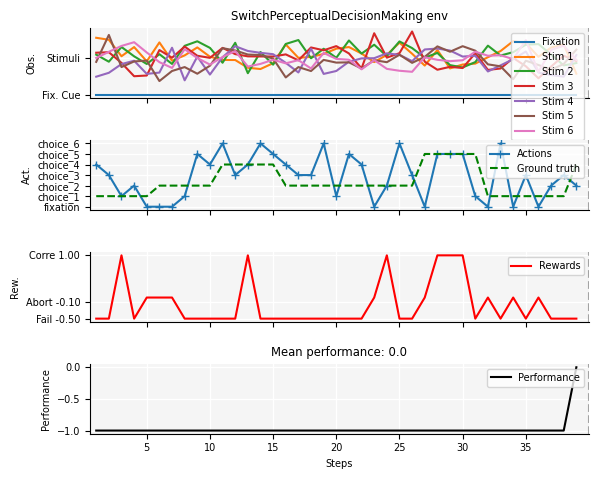

In [3]:
# Environment parameters
# This setting is low to speed up testing, we recommend setting it to at least 1000
dt = 100
dim_ring = 6  # Number of choices in the ring representation


kwargs = {'dt': dt, 'dim_ring': dim_ring}

env = SwitchPerceptualDecisionMaking(**kwargs)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env.timing)

print("\nObservation space structure:")
print(env.observation_space)

print("\nAction space structure:")
print(env.action_space)
print("Action mapping:")
print(env.action_space.name)

obs, info = env.reset()

stims = [f'Stim {i}' for i in range(1, kwargs['dim_ring'] + 1)]
# Visualize example trials
fig = plot_env(
    env,
    name='SwitchPerceptualDecisionMaking',
    ob_traces=['Fixation'] + stims,
    num_trials=1,
)

In [ ]:
# Make supervised dataset
seq_len = 100
device = 'cuda:0'
dataset = ngym.Dataset(env, batch_size=16,
                       seq_len=seq_len)
env = dataset.env
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n
eval_monitor = Monitor(env)
EVAL_TRIALS = 100
print("\nEvaluating random policy performance...")
metrics = eval_monitor.evaluate_policy(num_trials=EVAL_TRIALS)
print(f"\nRandom policy metrics ({EVAL_TRIALS:,} trials):")
print(f"Mean performance: {metrics['mean_performance']:.4f}")
print(f"Mean reward: {metrics['mean_reward']:.4f}")


Evaluating random policy performance...

Random policy metrics (100 trials):
Mean performance: 0.0000
Mean reward: 0.1500


In [16]:

def test(env, net, num_trial=100, device='cuda:0'):
    net.eval()
    perf = 0
    for i in range(num_trial):
        env.new_trial()
        ob, gt = env.ob, env.gt
        # print('obs:', ob.shape, ob)
        # print('gt:', gt.shape, gt)
        ob = ob[:, np.newaxis, :]  # Add batch axis
        inputs = torch.from_numpy(ob).type(torch.float).to(device)
        action_pred = net(inputs)[0]
        action_pred = action_pred.cpu().detach().numpy()
        action_pred = np.argmax(action_pred, axis=-1)
        perf += (gt[0:] == action_pred[0:,0]).mean()

    perf /= num_trial
    print('Average performance in {:d} trials: {:2f}'.format(num_trial, perf))
    return perf


def plot_test_performance(test_EI_acc, test_simple_acc, show_values=True):
    mean_ei = np.mean(test_EI_acc, axis=0)
    std_ei = np.std(test_EI_acc, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(test_simple_acc, axis=0)
    std_simple = np.std(test_simple_acc, axis=0)

    width = 0.35  # bar width

    fig, ax = plt.subplots(figsize=(4,4))
    bars = ax.bar(np.arange(2), [mean_ei, mean_simple], yerr=[std_ei, std_simple], width=width, capsize=4)
    ax.set_xticks(np.arange(2), labels=['EI', 'Simple'])
    # bars_ei = ax.bar(height=mean_ei, width=width,
    #                  yerr=std_ei, capsize=4,
    #                  label='EI')
    # bars_simple = ax.bar(height=mean_simple, width=width,
    #                      yerr=std_simple, capsize=4,
    #                      label='Simple')

    ax.set_ylabel('Test accuracy')
    # ax.set_title('Model comparison across environments')
    ax.legend()

    if show_values:
        ax.bar_label(bars, fmt='%.2f', padding=2)

    plt.tight_layout()
    # plt.savefig('./output/multitask/yang19_test_performance.png')
    plt.show()

In [15]:
test(env, net)

obs: (43, 7) [[1.         0.         0.         0.         0.         0.
  0.        ]
 [0.         0.46334946 0.6501073  0.8759702  0.44399273 0.4880352
  0.27502334]
 [0.         0.514372   0.64314294 0.6797125  0.36977005 0.17829633
  0.50589305]
 [0.         0.6190624  0.65969974 0.6568839  0.42942035 0.43869346
  0.4702487 ]
 [0.         0.40584716 0.67775553 0.507467   0.44070187 0.34810552
  0.64002347]
 [0.         0.4940598  0.615328   0.5345338  0.4097924  0.5507947
  0.48424217]
 [0.         0.6293061  0.6343419  0.32021832 0.45696852 0.30277637
  0.4660662 ]
 [0.         0.41844493 0.5671418  0.55031854 0.58926797 0.58706796
  0.65571797]
 [0.         0.4008635  0.5090832  0.44080907 0.26138225 0.5712151
  0.59132755]
 [0.         0.4945756  0.47717044 0.4860989  0.4423114  0.48957184
  0.32426554]
 [0.         0.5222096  0.45386836 0.6556053  0.6049757  0.5482241
  0.6669593 ]
 [0.         0.6286321  0.5184197  0.49701053 0.5553304  0.61346895
  0.5514746 ]
 [0.         0.

np.float64(0.6641860465116283)

In [6]:
from pdm_model import Net, SimpleNet
from pdm_train import train
n_seed = 5
epochs = 1000
lyapunov_every = 100
test_EI_performance = np.zeros((n_seed, ))
test_simple_performance = np.zeros((n_seed, ))
loss_log_ei = np.zeros((n_seed, epochs, 3))
loss_log_simple = np.zeros((n_seed, epochs, 3))

gradient_log_ei = np.zeros((n_seed, epochs, 1))
gradient_log_simple = np.zeros((n_seed, epochs, 1))

spectral_radius_log_ei = np.zeros((n_seed, epochs, 1))
spectral_radius_log_simple = np.zeros((n_seed, epochs, 1))

rec_balance_log_ei = np.zeros((n_seed, epochs, seq_len))
rec_balance_log_simple = np.zeros((n_seed, epochs, seq_len))

hidden_size = 128

lyapunov_spectrum_log_ei = np.zeros((n_seed, epochs // lyapunov_every, hidden_size))  # Track Lyapunov spectrum for EI
lyapunov_spectrum_log_simple = np.zeros((n_seed, epochs // lyapunov_every, hidden_size))  # Track Lyapunov spectrum for simple


for seed in range(n_seed):
    print(f"Seed {seed + 1}/{n_seed}")
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Create the model

    net = Net(ob_size=ob_size, num_h=hidden_size, act_size=act_size, entropy_loss=True).to(device)
    simple_net = SimpleNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size).to(device)

    net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(env, net, epochs, lyapunov_every)
    loss_log_ei[seed, :, :] = loss_log
    gradient_log_ei[seed, :, :] = gradient_log
    spectral_radius_log_ei[seed, :, :] = spectral_radius_log
    rec_balance_log_ei[seed, :, :] = rec_balance_log
    lyapunov_spectrum_log_ei[seed, :, :] = lyanpunov_spectrum_log
    simple_net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(env, simple_net, epochs, lyapunov_every)
    loss_log_simple[seed, :, :] = loss_log
    gradient_log_simple[seed, :, :] = gradient_log
    spectral_radius_log_simple[seed, :, :] = spectral_radius_log
    rec_balance_log_simple[seed, :, :] = rec_balance_log
    lyapunov_spectrum_log_simple[seed, :, :] = lyanpunov_spectrum_log

    test_EI_performance[seed] = test(env, net)
    test_simple_performance[seed] = test(env, simple_net)

Seed 1/5
Epoch [0/1000], Loss: 2.6529
Epoch [100/1000], Loss: 1.4292
Epoch [200/1000], Loss: 1.1608
Epoch [300/1000], Loss: 0.9947
Epoch [400/1000], Loss: 1.0028
Epoch [500/1000], Loss: 0.9444
Epoch [600/1000], Loss: 0.8782
Epoch [700/1000], Loss: 0.8840
Epoch [800/1000], Loss: 0.8995
Epoch [900/1000], Loss: 0.9271
Finished Training
Epoch [0/1000], Loss: 2.0129
Epoch [100/1000], Loss: 1.3175
Epoch [200/1000], Loss: 1.0349
Epoch [300/1000], Loss: 1.4133
Epoch [400/1000], Loss: 1.0430
Epoch [500/1000], Loss: 0.9592
Epoch [600/1000], Loss: 0.9869
Epoch [700/1000], Loss: 0.9612
Epoch [800/1000], Loss: 0.9555
Epoch [900/1000], Loss: 0.9048
Finished Training
Average performance in 100 trials: 0.671628
Average performance in 100 trials: 0.650233
Seed 2/5
Epoch [0/1000], Loss: 2.6596
Epoch [100/1000], Loss: 1.4595
Epoch [200/1000], Loss: 1.1675
Epoch [300/1000], Loss: 0.9987
Epoch [400/1000], Loss: 0.9636
Epoch [500/1000], Loss: 0.9445
Epoch [600/1000], Loss: 0.9159
Epoch [700/1000], Loss: 0.9

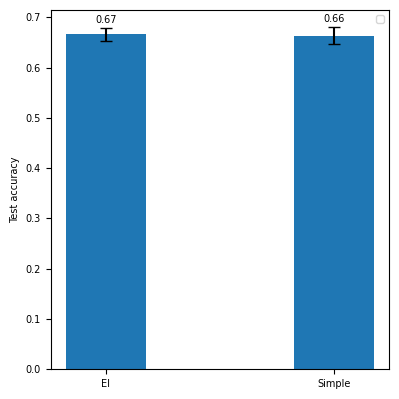

In [17]:
plot_test_performance(test_EI_performance, test_simple_performance, show_values=True)

In [8]:

def plot_loss_curve(loss_log_ei, gradient_log_ei, loss_log_simple, gradient_log_simple,
                    spectral_radius_log_ei=None, spectral_radius_log_simple=None,
                    rec_balance_log_ei=None, rec_balance_log_simple=None):
    fig, ax = plt.subplots(1,4, figsize=(20, 5))
    fontsize = 15
    ax = ax.flatten()
    mean_ei = np.mean(loss_log_ei, axis=0)
    std_ei = np.std(loss_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(loss_log_simple, axis=0)
    std_simple = np.std(loss_log_simple, axis=0)
    ax[0].plot(mean_ei[:, 0], label='EI', color='C0')
    ax[0].fill_between(np.arange(len(mean_ei)), mean_ei[:, 0] - std_ei[:, 0], mean_ei[:, 0] + std_ei[:, 0], alpha=0.2, color='C0')
    ax[0].plot(mean_simple[:, 0], label='simple', color='C1')
    ax[0].fill_between(np.arange(len(mean_simple)), mean_simple[:, 0] - std_simple[:, 0], mean_simple[:, 0] + std_simple[:, 0], alpha=0.2, color='C1')
    ax[0].set_title('Loss', fontsize=fontsize)
    ax[0].set_xlabel('Epoch', fontsize=fontsize)
    ax[0].legend(fontsize=fontsize)

    mean_ei = np.mean(gradient_log_ei, axis=0)
    std_ei = np.std(gradient_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(gradient_log_simple, axis=0)
    std_simple = np.std(gradient_log_simple, axis=0)
    log_mean_ei = np.log(mean_ei[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    log_mean_simple = np.log(mean_simple[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    log_std_ei = np.log(std_ei[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    log_std_simple = np.log(std_simple[:, 0] + 1e-10)  # Add small constant to avoid log(0)
    ax[1].plot(log_mean_ei, label='EI', color='C0')
    ax[1].fill_between(np.arange(len(mean_ei)), log_mean_ei - log_std_ei, log_mean_ei + log_std_ei, alpha=0.2, color='C0')
    ax[1].plot(log_mean_simple, label='simple', color='C1')
    ax[1].fill_between(np.arange(len(mean_simple)), log_mean_simple - log_std_simple, log_mean_simple + log_std_simple, alpha=0.2, color='C1')
    ax[1].set_title('Log Gradient norm', fontsize=fontsize)
    ax[1].set_xlabel('Epoch', fontsize=fontsize)
    ax[1].legend(fontsize=fontsize)

    if spectral_radius_log_ei is not None and spectral_radius_log_simple is not None:
        mean_ei = np.mean(spectral_radius_log_ei, axis=0)
        std_ei = np.std(spectral_radius_log_ei, axis=0)
        mean_simple = np.mean(spectral_radius_log_simple, axis=0)
        std_simple = np.std(spectral_radius_log_simple, axis=0)
        ax[2].plot(mean_ei[:, 0], label='EI', color='C0')
        ax[2].fill_between(np.arange(len(mean_ei)), mean_ei[:, 0] - std_ei[:, 0], mean_ei[:, 0] + std_ei[:, 0], alpha=0.2, color='C0')
        ax[2].plot(mean_simple[:, 0], label='simple', color='C1')
        ax[2].fill_between(np.arange(len(mean_simple)), mean_simple[:, 0] - std_simple[:, 0], mean_simple[:, 0] + std_simple[:, 0], alpha=0.2, color='C1')
        ax[2].set_title('Spectral radius', fontsize=fontsize)
        ax[2].set_xlabel('Epoch', fontsize=fontsize)
        ax[2].legend(fontsize=fontsize)

    if rec_balance_log_ei is not None and rec_balance_log_simple is not None:
        mean_ei = np.mean(rec_balance_log_ei, axis=(0,-1))
        std_ei = np.std(rec_balance_log_ei, axis=(0,-1))
        mean_simple = np.mean(rec_balance_log_simple, axis=(0,-1))
        std_simple = np.std(rec_balance_log_simple, axis=(0,-1))
        ax[3].plot(mean_ei, label='EI', color='C0')
        ax[3].fill_between(np.arange(len(mean_ei)), mean_ei - std_ei, mean_ei + std_ei, alpha=0.2, color='C0')
        ax[3].plot(mean_simple, label='simple', color='C1')
        ax[3].fill_between(np.arange(len(mean_simple)), mean_simple - std_simple, mean_simple + std_simple, alpha=0.2, color='C1')
        ax[3].set_title('Recurrent balance', fontsize=fontsize)
        ax[3].set_xlabel('Epoch', fontsize=fontsize)
        ax[3].legend(fontsize=fontsize)

    for a in ax:
        a.tick_params(labelsize=fontsize)

    plt.tight_layout()
    # plt.savefig('./output/multitask/yang19_loss_curve.png')
    plt.show()

def plot_lyapunov_spectrum(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple):
    n_lyapunov = lyapunov_spectrum_log_ei.shape[1]
    hidden_size = lyapunov_spectrum_log_ei.shape[2]
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    fontsize = 15
    mean_ei = np.mean(lyapunov_spectrum_log_ei, axis=0)
    std_ei = np.std(lyapunov_spectrum_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(lyapunov_spectrum_log_simple, axis=0)
    std_simple = np.std(lyapunov_spectrum_log_simple, axis=0)
    argsort_ei = np.flip(np.argsort(mean_ei, axis=1), axis=1)
    argsort_simple = np.flip(np.argsort(mean_simple, axis=1), axis=1)
    sorted_mean_ei = np.take_along_axis(mean_ei, argsort_ei, axis=1)
    sorted_std_ei = np.take_along_axis(std_ei, argsort_ei, axis=1)
    sorted_mean_simple = np.take_along_axis(mean_simple, argsort_simple, axis=1)
    sorted_std_simple = np.take_along_axis(std_simple, argsort_simple, axis=1)
    alpha_list = np.linspace(0.1, 1.0, n_lyapunov)
    for i in range(n_lyapunov):
        ax[0].plot(sorted_mean_ei[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C0')
        ax[0].plot(sorted_mean_simple[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C1')
        # ax[0].fill_between(np.arange(hidden_size), sorted_mean_ei[i] - sorted_std_ei[i], sorted_mean_ei[i] + sorted_std_ei[i], alpha=0.2, color='C0')
        ax[1].plot(sorted_mean_simple[i], label=f'Lyapunov {i+1}', alpha=alpha_list[i], color='C1')
        # ax[1].fill_between(np.arange(hidden_size), sorted_mean_simple[i] - sorted_std_simple[i], sorted_mean_simple[i] + sorted_std_simple[i], alpha=0.2, color='C1')
    # ax[0].set_title('Lyapunov spectrum (EI)', fontsize=fontsize)
    ax[1].set_title('Lyapunov spectrum (simple)', fontsize=fontsize)
    ax[0].set_xlabel('Lyapunov index', fontsize=fontsize)
    ax[1].set_xlabel('Lyapunov index', fontsize=fontsize)
    ax[0].set_ylabel('Lyapunov exponent', fontsize=fontsize)
    ax[1].set_ylabel('Lyapunov exponent', fontsize=fontsize)
    # ax[0].legend(fontsize=fontsize)
    # ax[1].legend(fontsize=fontsize)
    for a in ax:
        a.tick_params(labelsize=fontsize)
    plt.tight_layout()
    # plt.savefig('./output/multitask/yang19_lyapunov_spectrum.png')
    plt.show()

def plot_lyapunov_spectrum_separately(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple):
    n_lyapunov = lyapunov_spectrum_log_ei.shape[1]
    hidden_size = lyapunov_spectrum_log_ei.shape[2]
    fig, ax = plt.subplots(4, 5, figsize=(16, 10), sharex=True)
    ax = ax.flatten()
    fontsize = 15
    mean_ei = np.mean(lyapunov_spectrum_log_ei, axis=0)
    std_ei = np.std(lyapunov_spectrum_log_ei, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(lyapunov_spectrum_log_simple, axis=0)
    std_simple = np.std(lyapunov_spectrum_log_simple, axis=0)
    argsort_ei = np.flip(np.argsort(mean_ei, axis=1), axis=1)
    argsort_simple = np.flip(np.argsort(mean_simple, axis=1), axis=1)
    sorted_mean_ei = np.take_along_axis(mean_ei, argsort_ei, axis=1)
    sorted_std_ei = np.take_along_axis(std_ei, argsort_ei, axis=1)
    sorted_mean_simple = np.take_along_axis(mean_simple, argsort_simple, axis=1)
    sorted_std_simple = np.take_along_axis(std_simple, argsort_simple, axis=1)
    # alpha_list = np.linspace(0.1, 1.0, n_lyapunov)
    for i in range(n_lyapunov):
        ax[i].plot(sorted_mean_ei[i], label='EI', color='C0')
        ax[i].fill_between(np.arange(hidden_size), sorted_mean_ei[i] - sorted_std_ei[i], sorted_mean_ei[i] + sorted_std_ei[i], alpha=0.2, color='C0')
        ax[i].plot(sorted_mean_simple[i], label='simple', color='C1')
        ax[i].fill_between(np.arange(hidden_size), sorted_mean_simple[i] - sorted_std_simple[i], sorted_mean_simple[i] + sorted_std_simple[i], alpha=0.2, color='C1')
        ax[i].set_title(f'Epoch {i+1}*100', fontsize=fontsize)
        if i > 14:
            ax[i].set_xlabel('Lyapunov index', fontsize=fontsize)
        if i % 5 == 0:
            ax[i].set_ylabel('Lyapunov exponent', fontsize=fontsize)
        ax[i].legend(fontsize=fontsize)
        ax[i].tick_params(labelsize=fontsize)
    plt.tight_layout()
    # plt.savefig('./output/multitask/yang19_lyapunov_spectrum_separately.png')
    plt.show()

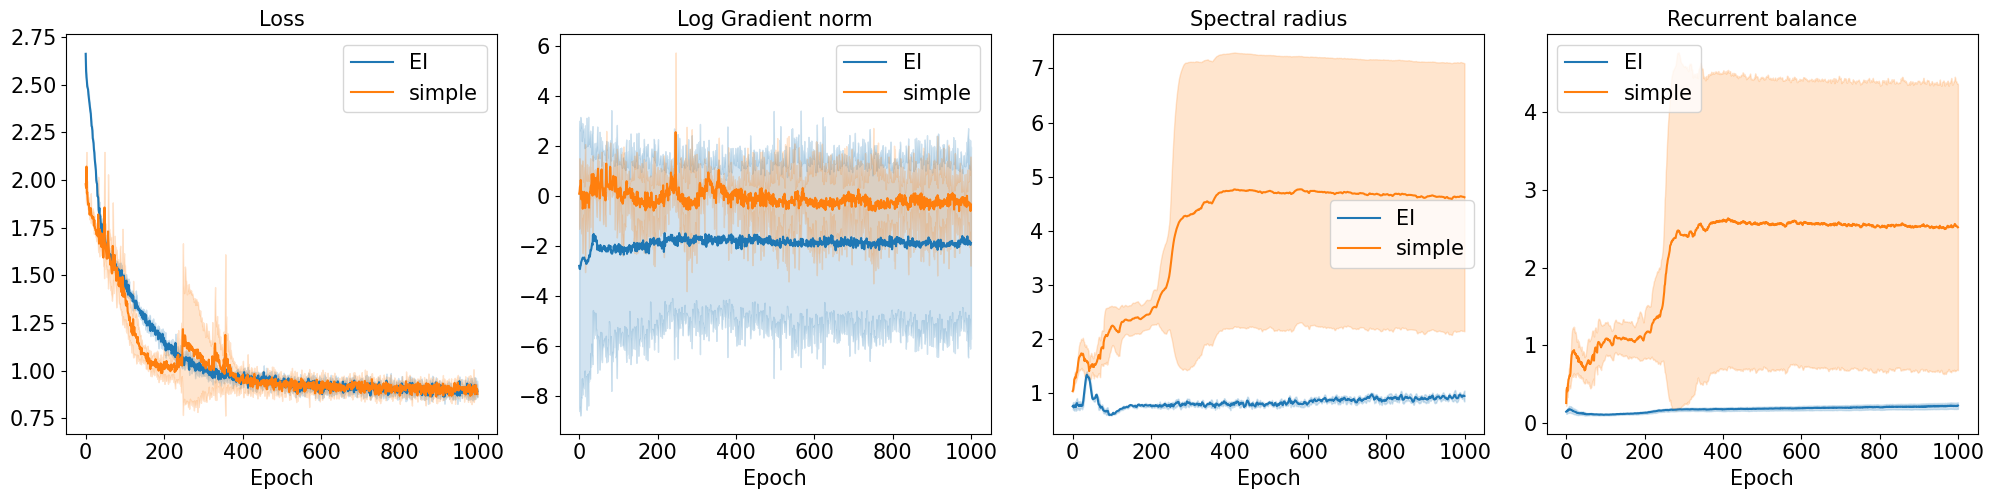

In [9]:
plot_loss_curve(loss_log_ei, gradient_log_ei,
                loss_log_simple, gradient_log_simple,
                spectral_radius_log_ei, spectral_radius_log_simple,
                rec_balance_log_ei, rec_balance_log_simple)

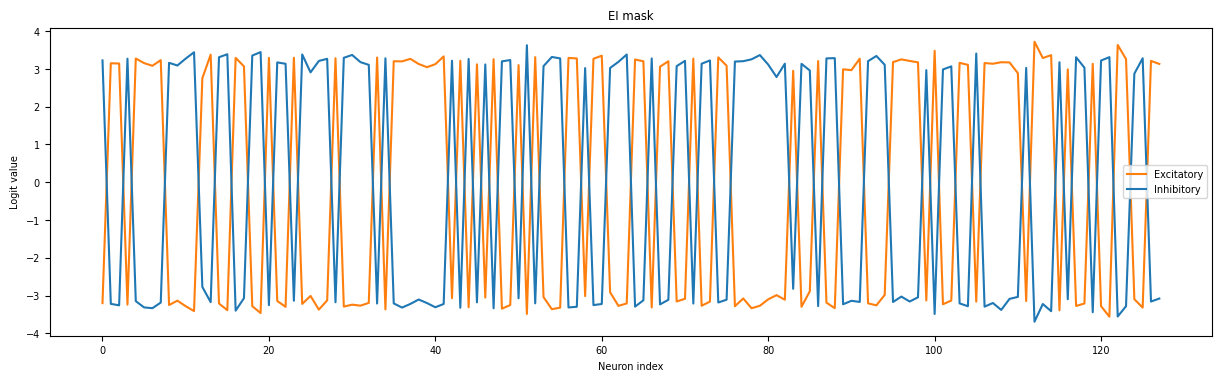

In [10]:
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
ei_code = np.where(eimask[:, 0] > eimask[:, 1], 1., -1.)
mask = np.where(ei_code.reshape(-1,1)>0, np.array([[1,0]]).repeat(eimask.shape[0], axis=0),
                np.array([[0,1]]).repeat(eimask.shape[0], axis=0))
fig, ax = plt.subplots(1,1,figsize=(15, 4))
ax.plot(eimask[:, 0], label='Excitatory', color='C1')
ax.plot(eimask[:, 1], label='Inhibitory', color='C0')
ax.set_title('EI mask')
ax.set_xlabel('Neuron index')
ax.set_ylabel('Logit value')
ax.legend()
plt.show()

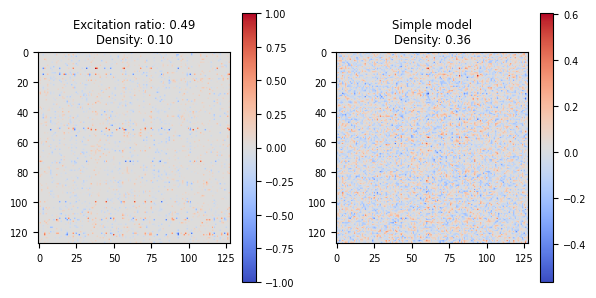

In [19]:
weight = net.get_actual_weight().detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
im = ax[0].imshow(weight, cmap='coolwarm', vmin=-1, vmax=1)
density = np.mean(np.abs(weight)>0.1)
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nDensity: {density:.2f}')
plt.colorbar(im, ax=ax[0])

weight_simple = simple_net.get_actual_weight().detach().cpu().numpy()
im = ax[1].imshow(weight_simple, cmap='coolwarm')
density_simple = np.mean(np.abs(weight_simple)>0.1)
ax[1].set_title(f'Simple model\nDensity: {density_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()


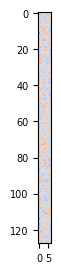

In [12]:
input_layer = net.lstm.input_layer.weight.detach().cpu().numpy()
fig, ax = plt.subplots(1, 1, figsize=(6, 3))
im = ax.imshow(input_layer, cmap='coolwarm', vmin=-1.5, vmax=1.5)


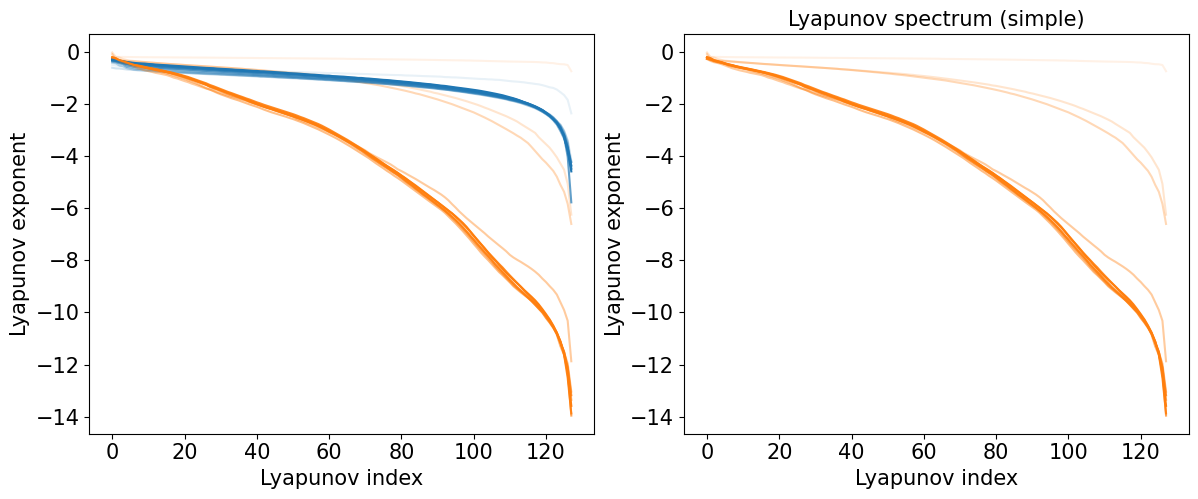

In [13]:
plot_lyapunov_spectrum(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple)